# Analisando Grafos do SNAP: `email-EuAll`

Notebook de orquestração do trabalho prático de Teoria dos Grafos (IC/UFBA).

**Grafo atribuído:** matrícula 224216275, com S = 2+2+4+2+1+6+2+7+5 = 31 e U = 75, então
(31 × 76) mod 129 = 2356 mod 129 = **34**, o que dá **G34 = `email-EuAll`** (SNAP).

Toda a lógica está nos módulos de `src/`. O notebook só executa o pipeline e exibe as
tabelas (`results/tables/`) e as figuras (`results/figures/`).

* `RECOMPUTE = False`: apenas carrega e exibe os resultados já gerados (rápido).
* `RECOMPUTE = True`: refaz tudo do zero (~1 h 15 min), executando cada módulo como em
  `python -m src.<modulo>`. Requer os dados brutos (`python scripts/download_data.py`).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.max_colwidth", 120)

RECOMPUTE = False


def run(module, *args):
    """Executa `python -m src.<module>` na raiz do projeto, se RECOMPUTE."""
    if not RECOMPUTE:
        return
    print(f"$ python -m src.{module}", *args)
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}  # saída com ∞, σ, γ no Windows
    r = subprocess.run([sys.executable, "-m", f"src.{module}", *args], cwd=ROOT, env=env,
                       capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-3000:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
    r.check_returncode()


def table(name):
    return pd.read_csv(TABLES / name)


def figure(name, width=900):
    display(Image(filename=str(FIGURES / name), width=width))

## 1. Tratamento dos dados

Remoção de auto-loops, conversão de dirigido para não dirigido simples e extração da
maior componente conexa (LCC). O dataset não tem timestamps nem arestas múltiplas, então
não há etapa temporal nem de multigrafo.

In [2]:
run("treatment")
run("prepare_data")
table("tratamento_evolucao.csv")

,etapa,vertices,arestas
0,Grafo bruto (dirigido),265214,420045
1,Após remoção de auto-loops (dirigido),265214,418956
2,Após conversão para não dirigido simples,265214,364481
3,Maior componente conexa (LCC),224832,339925


## 2. Parte I: análise estrutural

In [3]:
run("metrics")
run("distances")
run("clustering")
run("visualize")
run("part1_summary")
table("parte1_resumo.csv")

,medida,grafo_completo,lcc,status,metodo
0,Número de vértices,265214,224832,Computado (exato),Contagem
1,Número de arestas,364481,339925,Computado (exato),Contagem (não dirigido simples)
2,Grau mínimo,0,1,Computado (exato),Lista de adjacência
3,Grau máximo,7636,7636,Computado (exato),Lista de adjacência
4,Grau médio,2.7486,3.0238,Computado (exato),2m/n
5,Distribuição de graus,-,ver figura,Computado (exato),distribuicao_graus.csv / distribuicao_graus.png
6,Densidade,1.036e-05,1.345e-05,Computado (exato),2m / (n(n-1))
7,Número de componentes conexas,15836,1,Computado (exato),BFS
8,Tamanho de cada componente,ver tabela,-,Computado (exato),componentes_tamanhos.csv / componentes_frequencia.csv
9,Diâmetro,∞ (desconexo),14,Computado (exato),"BoundingDiameters (Takes & Kosters, 2011), 4 BFS; no grafo completo é infinito por ser desconexo"


In [4]:
display(table("parte1_basicas.csv"))
display(table("parte1_diametro_raio.csv"))
display(table("parte1_caminho_exato.csv"))   # L exato (redução das folhas)
display(table("parte1_caminhos_amostragem.csv"))   # estimativa, para validação
table("parte1_clusterizacao.csv")

,metrica,grafo_completo,lcc
0,vertices,265214.00000,224832.000000
1,arestas,364481.00000,339925.000000
2,grau_min,0.00000,1.000000
3,grau_max,7636.00000,7636.000000
4,grau_medio,2.74858,3.023813
5,densidade,0.00001,0.000013
6,componentes,15836.00000,1.000000
7,maior_componente,224832.00000,224832.000000
8,menor_componente,1.00000,224832.000000


,diametro_lo,diametro_up,raio_lo,raio_up,bfs,exato,tempo_s
0,14,14,7,7,4,True,0.65031


,L_exato,soma_distancias,bfs_executadas,folhas_deduzidas,tempo_s
0,4.11821,208172243264,36536,188296,1347.95318


,k,L_medio,L_desvio,L_ic95_inf,L_ic95_sup,ecc_max_amostra,ecc_min_amostra,tempo_s
0,100,4.117795,0.412131,4.037017,4.198572,13,9,14.690728
1,500,4.127090,0.334097,4.097805,4.156375,13,8,73.994278


,escopo,triangulos,clusterizacao_media,transitividade,vertices_em_triangulos,tempo_s
0,grafo_completo,267313,0.067085,0.004106,25132,1.055725
1,lcc,267313,0.079134,0.004163,25132,0.817946


### Tamanho das componentes conexas (grafo completo)

,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
tamanho,1,2,3,4,5,6,7,8,9,10,...,35,38,40,43,45,62,86,1373,1850,224832
quantidade,205,13276,1426,403,172,100,53,40,32,25,...,1,1,1,1,1,1,1,1,1,1


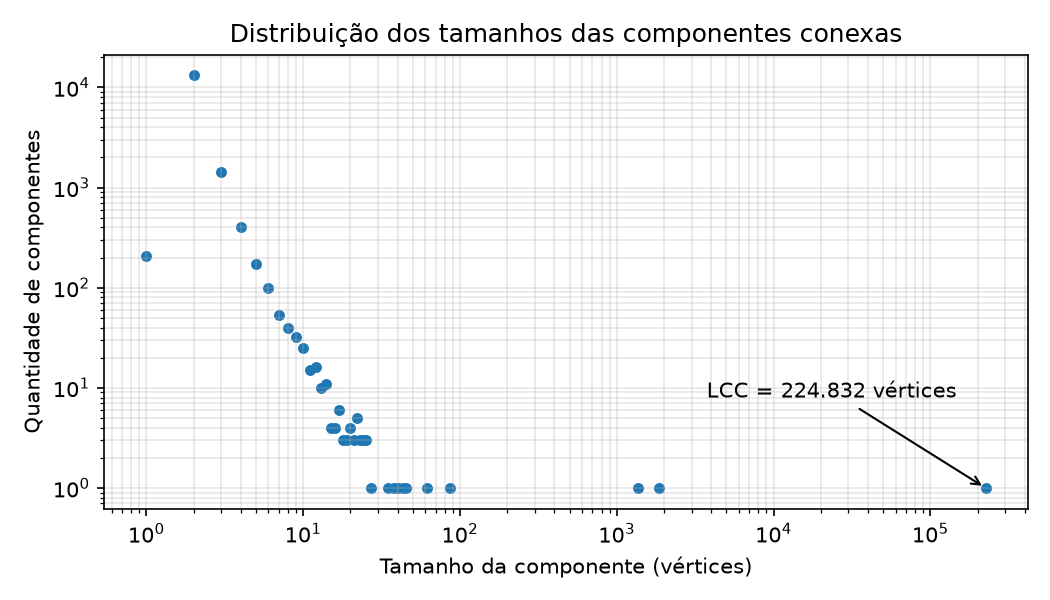

In [5]:
display(table("componentes_frequencia.csv").T)
figure("componentes_tamanhos.png", 700)

### Distribuição de graus e visualização (amostra de 300 vértices)

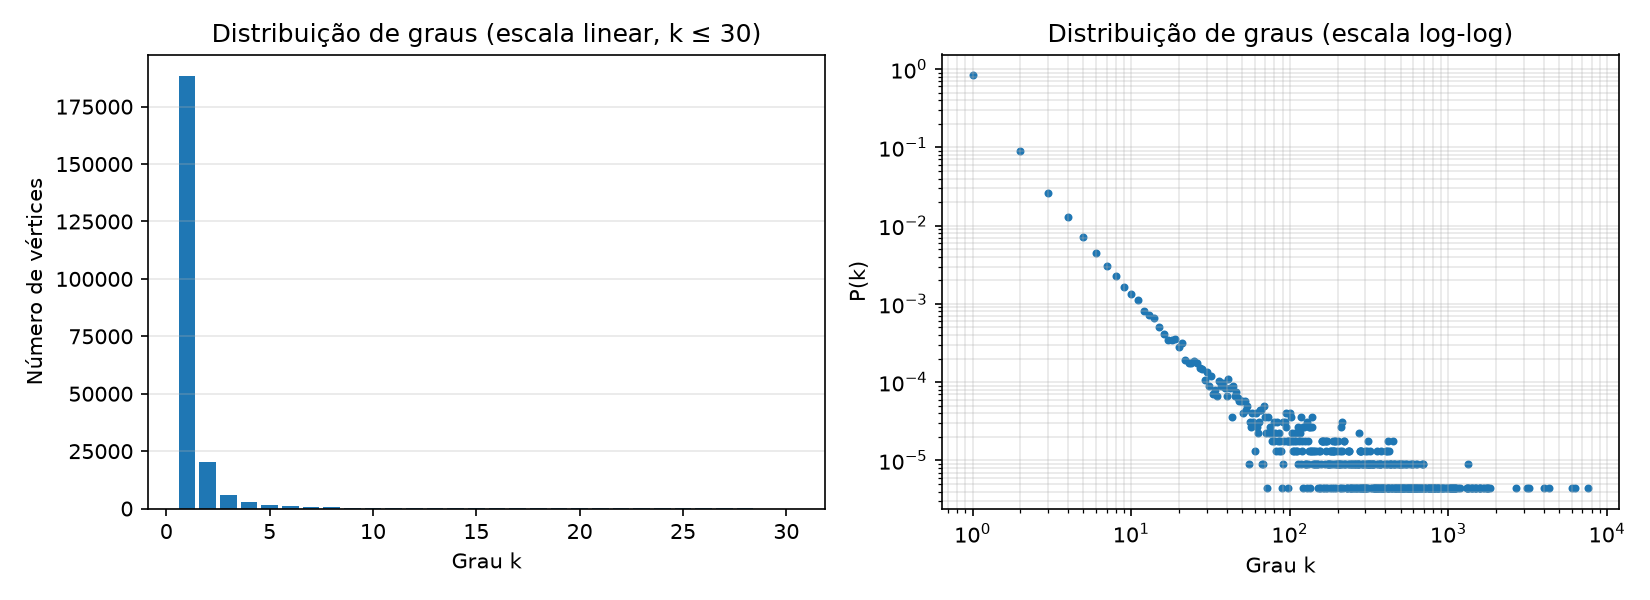

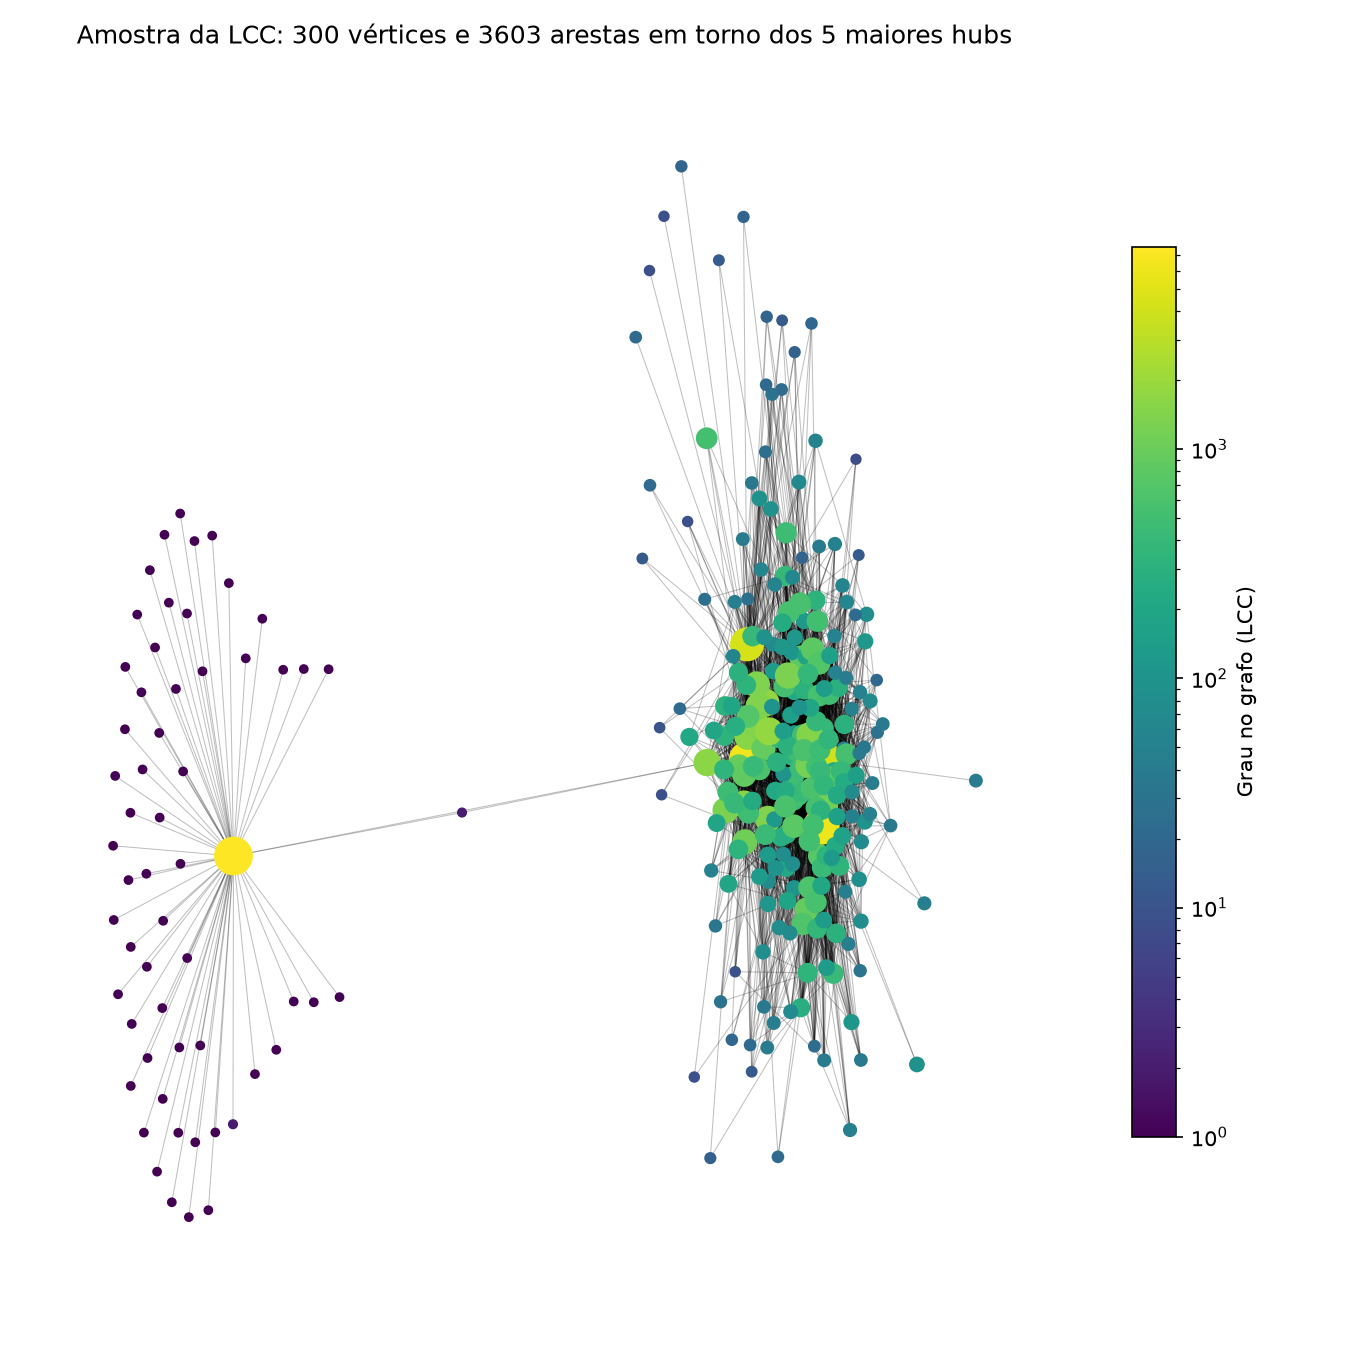

In [6]:
figure("distribuicao_graus.png")
figure("visualizacao_amostra.png", 650)

## 3. Parte II: algoritmos

Implementações próprias em `src/algorithms/`, conferidas com o NetworkX em `tests/`.
Tempos: 30 execuções (IC 95% Normal/Z) e 10 no Floyd-Warshall em Python puro
(IC 95% t-Student). Pesos derivados da reciprocidade: 1 se o par trocou e-mail nos dois
sentidos, 2 se a comunicação foi de mão única.

In [7]:
run("benchmark")
table("parte2_tempos.csv")

,algoritmo,grafo,V,E,complexidade,n,media_s,desvio_s,ic95_inf_s,ic95_sup_s,distribuicao,valor_critico
0,BFS,LCC,224832,339925,O(V+E),30,0.174897,0.008271,0.171937,0.177857,Normal (Z),1.960000
1,DFS (iterativa),LCC,224832,339925,O(V+E),30,0.337154,0.027451,0.327331,0.346977,Normal (Z),1.960000
2,Eulerianidade (não dirigido),LCC,224832,339925,O(V+E),30,0.183778,0.040093,0.169431,0.198126,Normal (Z),1.960000
3,Eulerianidade (dirigido),G_dir,265214,418956,O(V+E),30,0.537117,0.021273,0.529504,0.544729,Normal (Z),1.960000
4,Dijkstra (heap),LCC ponderada,224832,339925,O((V+E) log V),30,0.691845,0.088774,0.660078,0.723613,Normal (Z),1.960000
5,Bellman-Ford,subgrafo 300,300,372,O(V·E),30,0.000292,0.000021,0.000284,0.000300,Normal (Z),1.960000
6,Floyd-Warshall (Python puro),subgrafo 300,300,372,O(V³),10,2.058272,0.063263,2.013017,2.103528,t-Student,2.262157
7,Floyd-Warshall (numpy),subgrafo 300,300,372,O(V³),30,0.059421,0.002807,0.058417,0.060426,Normal (Z),1.960000
8,Tarjan (SCC),G_dir,265214,418956,O(V+E),30,0.641971,0.042670,0.626701,0.657240,Normal (Z),1.960000
9,Tarjan (pontes/articulações),LCC,224832,339925,O(V+E),30,0.577524,0.041995,0.562496,0.592552,Normal (Z),1.960000


In [8]:
table("parte2_resultados.csv")

,algoritmo,grafo,resultado
0,BFS,LCC,visitou 224832 vértices; profundidade máx. 10
1,DFS (iterativa),LCC,visitou 224832 vértices
2,Eulerianidade (não dirigido),LCC,não euleriano; 198520 vértices de grau ímpar
3,Eulerianidade (dirigido),G_dir,não euleriano; 242614 vértices com entrada≠saída; fracamente conexo=False
4,Dijkstra (heap),LCC ponderada,alcançou 224832 vértices; dist. máx. 18
5,Bellman-Ford,subgrafo 300,alcançou 300 vértices; 2 rodadas
6,Floyd-Warshall (Python puro),subgrafo 300,matriz 300×300; dist. máx. 4
7,Floyd-Warshall (numpy),subgrafo 300,matriz 300×300; dist. máx. 4
8,Tarjan (SCC),G_dir,231000 SCCs; maior com 34203 vértices
9,Tarjan (pontes/articulações),LCC,188668 pontes; 2223 articulações


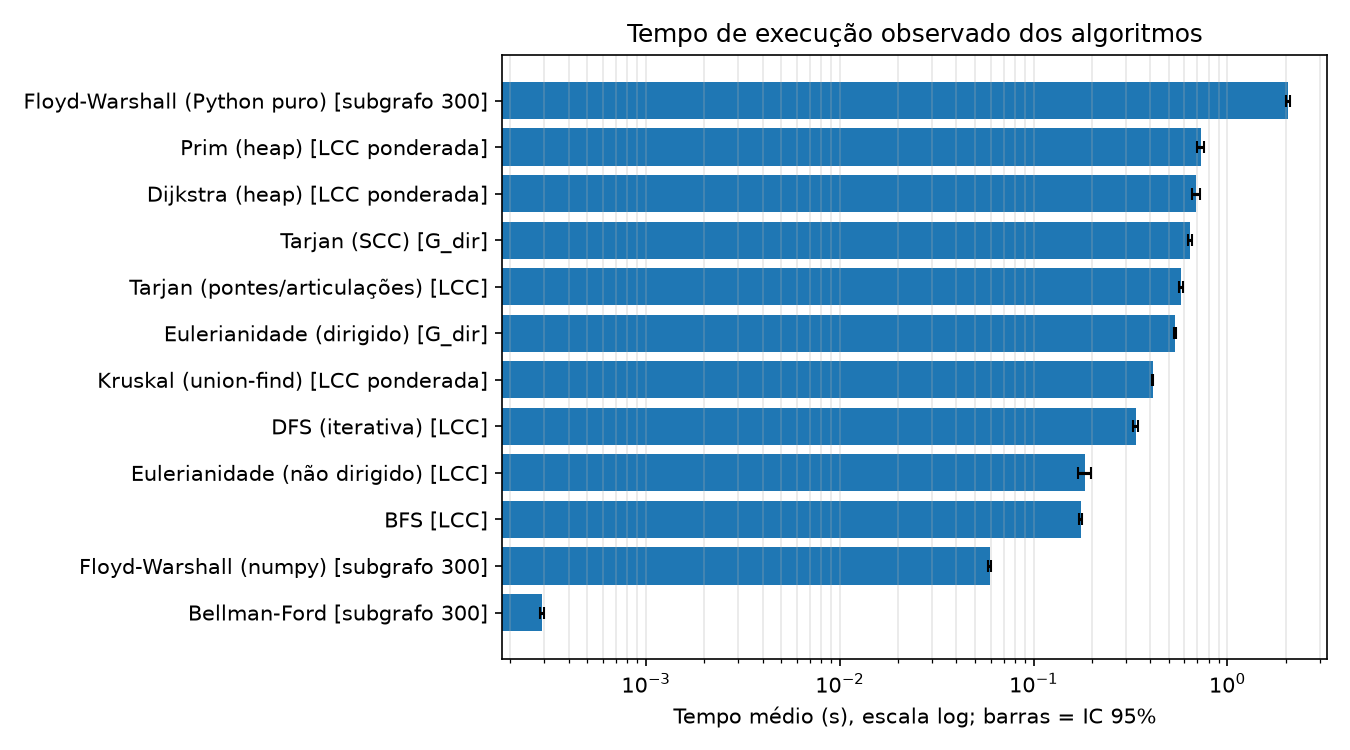

,algoritmo,funcao_teorica,expoente_vs_f,R2_vs_f,V_min,V_max,pontos,rodadas_min,rodadas_max
0,BFS,V+E,1.526581,0.999099,14000,224832,5,NaN,NaN
1,DFS,V+E,1.322885,0.999407,14000,224832,5,NaN,NaN
2,Eulerianidade,V+E,1.472456,0.999474,14000,224832,5,NaN,NaN
3,Tarjan (pontes/articulações),V+E,1.135208,0.999778,14000,224832,5,NaN,NaN
4,Dijkstra,(V+E) log V,1.347735,0.999748,14000,224832,5,NaN,NaN
5,Prim,E log V,1.126950,0.999720,14000,224832,5,NaN,NaN
6,Kruskal,E log V,1.113561,0.999374,14000,224832,5,NaN,NaN
7,Bellman-Ford,V·E,0.563424,0.991963,1000,16000,5,3.0,3.0
8,Floyd-Warshall,V³,0.994696,0.999856,50,300,6,NaN,NaN
9,Floyd-Warshall (numpy),V³,1.223778,0.996977,250,1000,4,NaN,NaN


,algoritmo,funcao_teorica,E_por_V_menor_grafo,E_por_V_maior_grafo,expoente_vs_f,expoente_vs_V,a_ns_por_vertice,b_ns_por_aresta,R2_aV_bE,erro_rel_max
0,BFS,V+E,4.730786,1.511907,1.526581,1.069204,800.258933,0.000000,0.994483,0.246962
1,DFS,V+E,4.730786,1.511907,1.322885,0.927267,1228.620325,88.362628,0.999967,0.020854
2,Eulerianidade,V+E,4.730786,1.511907,1.472456,1.031848,787.523258,0.000000,0.997839,0.126150
3,Tarjan (pontes/articulações),V+E,4.730786,1.511907,1.135208,0.794952,1612.450228,537.368468,0.999945,0.036033
4,Dijkstra,(V+E) log V,4.730786,1.511907,1.347735,1.067970,2709.339082,0.000000,0.995979,0.187764
5,Prim,E log V,4.730786,1.511907,1.126950,0.763434,1653.820594,1062.846288,0.999532,0.065180
6,Kruskal,E log V,4.730786,1.511907,1.113561,0.753967,1077.074110,607.834100,0.999809,0.016431


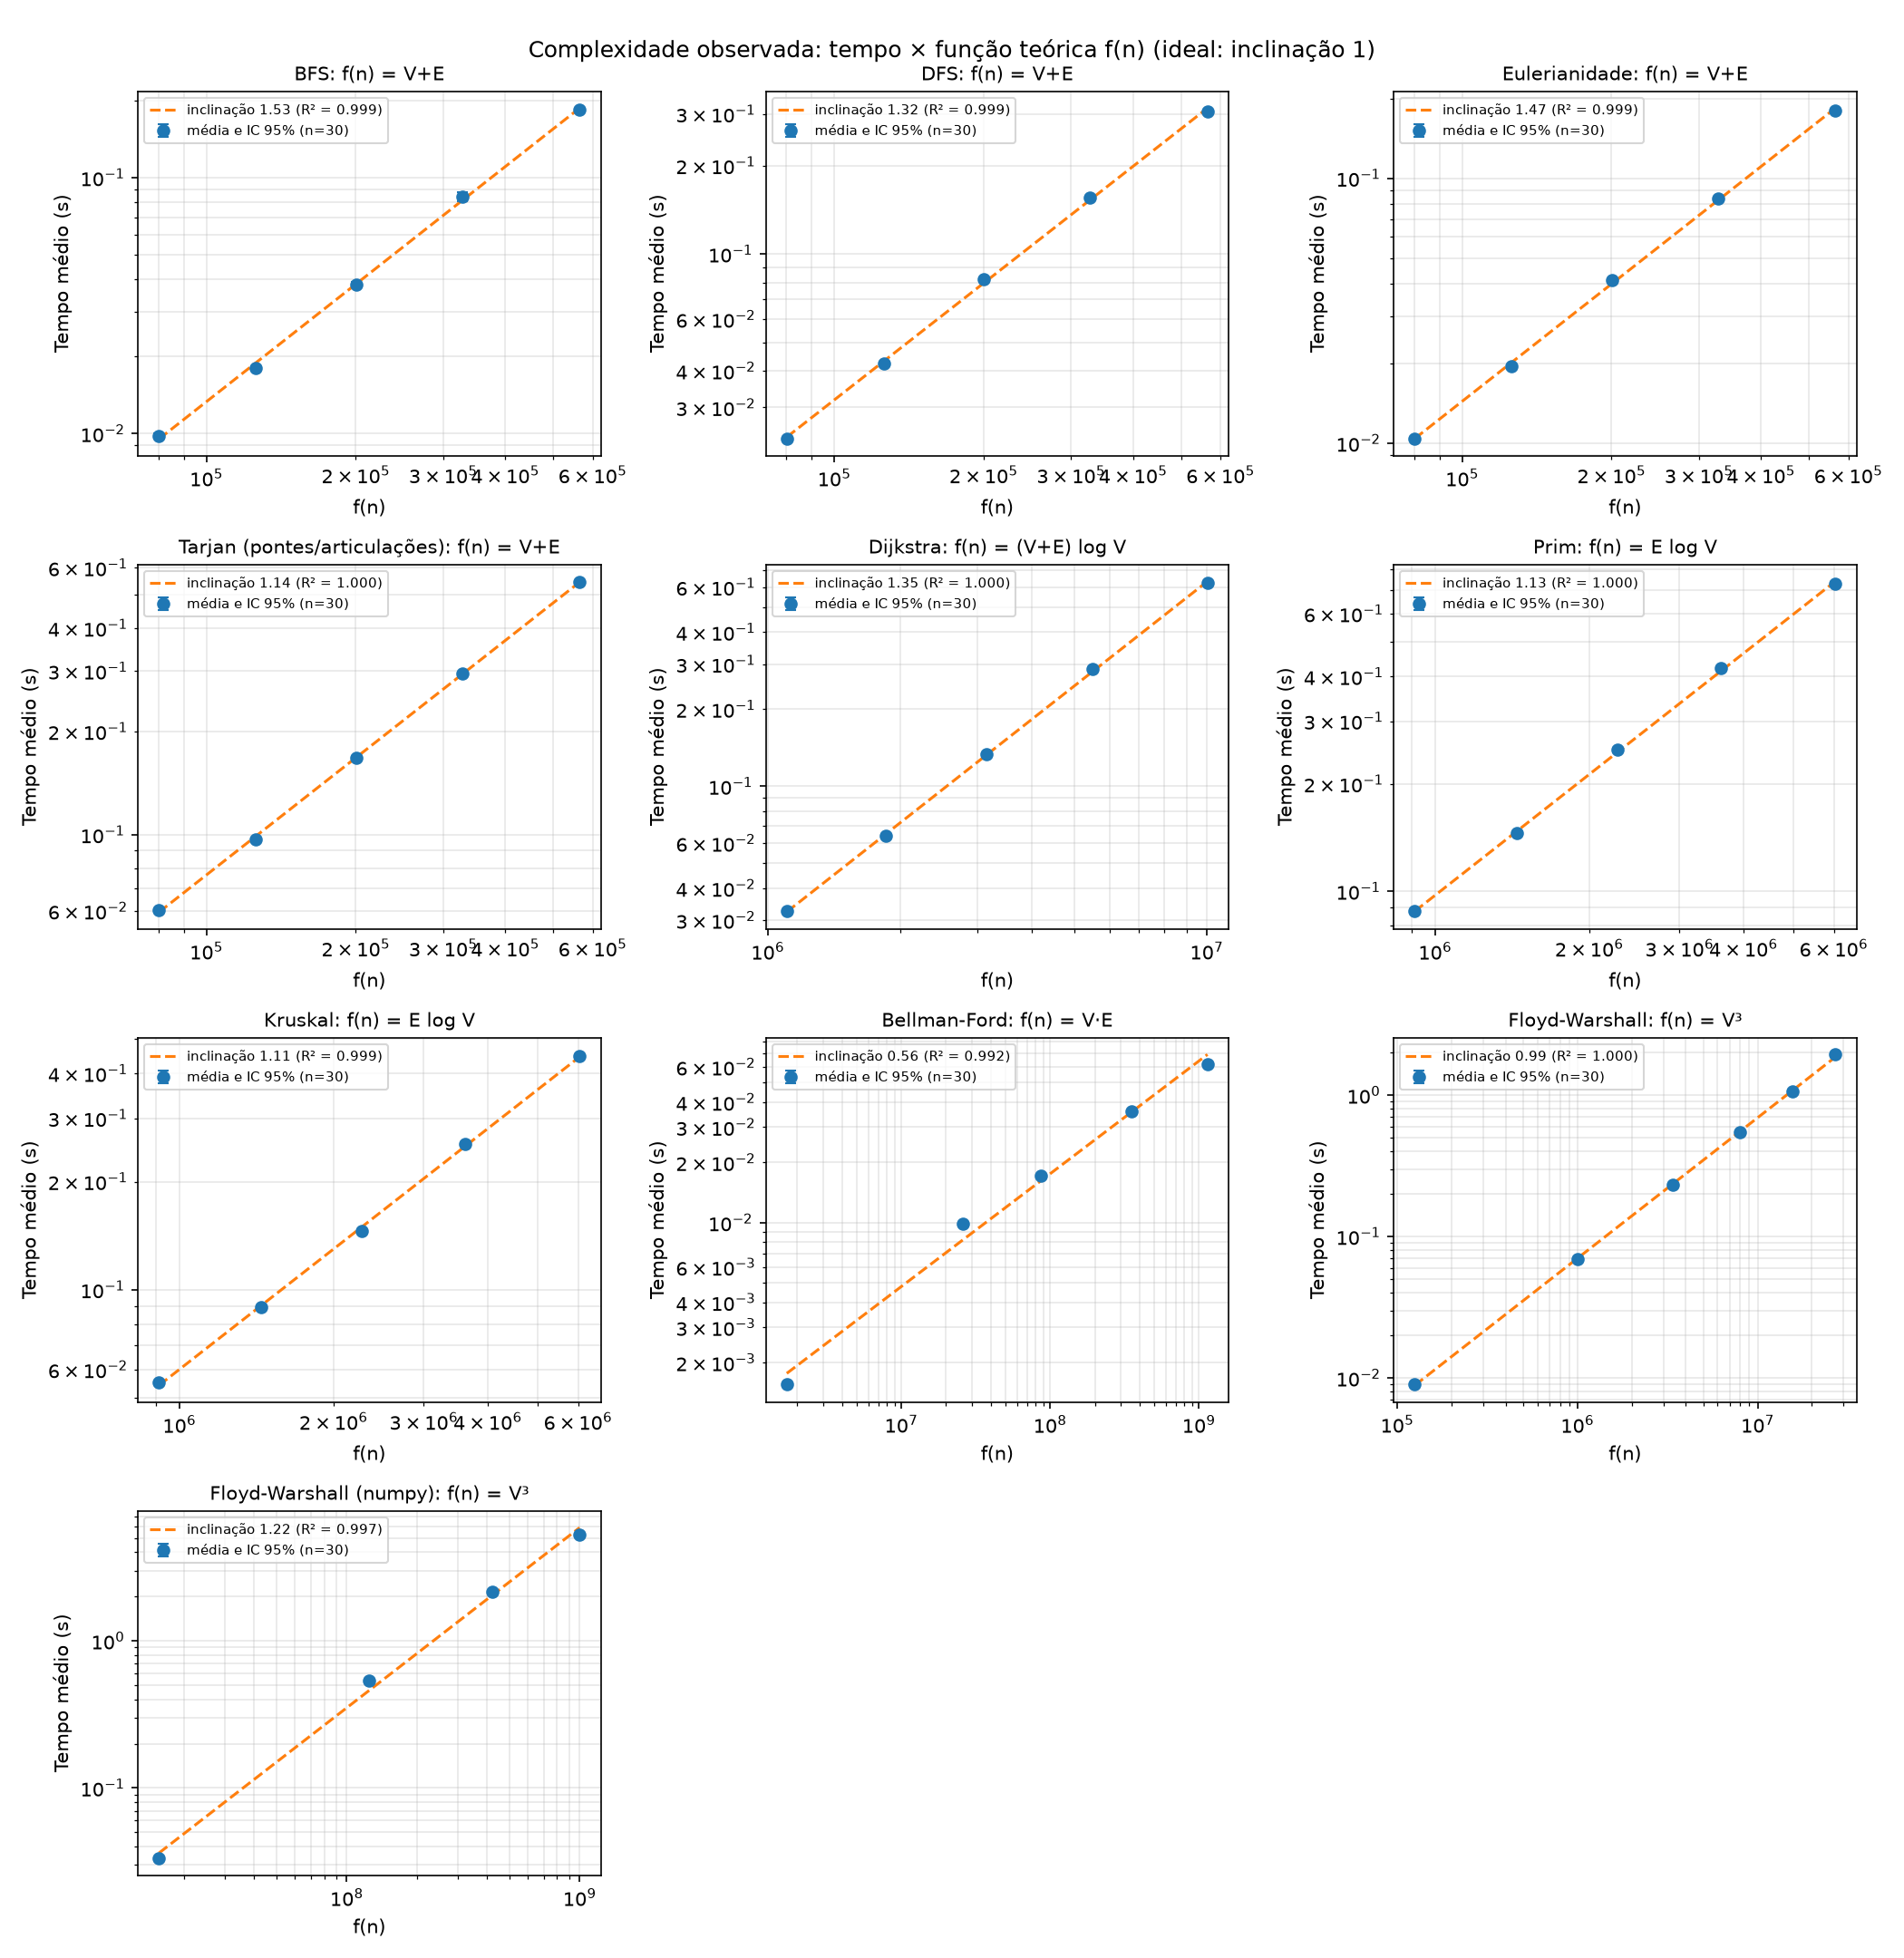

In [9]:
figure("tempos_algoritmos.png", 750)
display(table("parte2_expoentes.csv"))
display(table("parte2_ajuste_vertices_arestas.csv"))   # t ≈ a·V + b·E (E/V varia)
figure("escala_algoritmos.png")

## 4. Parte III: propriedades da rede

### 4.1 Small-world

In [10]:
run("smallworld")
display(table("parte3_smallworld.csv"))      # ER e reconexão que preserva os graus
display(table("parte3_smallworld_er.csv"))
table("parte3_smallworld_config.csv")

,metrica,real,er_medido,er_analitico,razao_real_er,config_medido,razao_real_config
0,Comprimento médio L,4.118210,11.115621,11.136828,0.370489,3.624083,1.136346
1,Clusterização média C,0.079134,0.000008,0.000013,10141.945694,0.033720,2.346810
2,σ = (C/C_r)/(L/L_r),27374.520712,NaN,15911.811840,NaN,2.065226,NaN


,realizacao,C,L,L_ic95_inf,L_ic95_sup,fracao_maior_componente
0,1,0.000008,11.072740,11.013443,11.132037,0.942103
1,2,0.000008,11.153166,11.082774,11.223558,0.941685
2,3,0.000007,11.110991,11.048019,11.173962,0.941757
3,4,0.000007,11.128118,11.064906,11.191330,0.942366
4,5,0.000009,11.113092,11.045754,11.180429,0.942259


,realizacao,trocas_aceitas,C,L,L_ic95_inf,L_ic95_sup,fracao_maior_componente
0,1,2579518,0.034070,3.611523,3.578050,3.644996,0.803738
1,2,2578145,0.033605,3.625401,3.589381,3.661422,0.801096
2,3,2580110,0.033484,3.635323,3.602293,3.668354,0.803053


### 4.2 Lei de potência

,metodo,gamma,R2,observacao
0,Regressão log-log de P(k) (log-binning),1.941660,0.982830,k ≥ 1
1,Regressão log-log da CCDF,2.027047,0.904035,k ≥ 1
2,"MLE discreta, k_min por KS (cabeça)",2.830789,NaN,k ≥ 1 (224832 vértices); KS = 0.0306; erro padrão = 0.0039
3,"MLE discreta, k_min ≥ 5 por KS (cauda)",1.740105,NaN,k ≥ 9 (3762 vértices); KS = 0.0523; erro padrão = 0.0121


,kmin,n_cauda,gamma_mle,erro_padrao,ks
0,1,224832,2.830789,0.003861,0.030618
1,2,36536,2.329514,0.006956,0.074343
2,3,16392,2.086467,0.008486,0.072345
3,5,7555,1.889749,0.010236,0.071308
4,10,3390,1.723388,0.012424,0.054930
5,20,1897,1.661313,0.015184,0.085588
6,50,1098,1.723430,0.021832,0.130396
7,100,805,1.938418,0.033075,0.116818


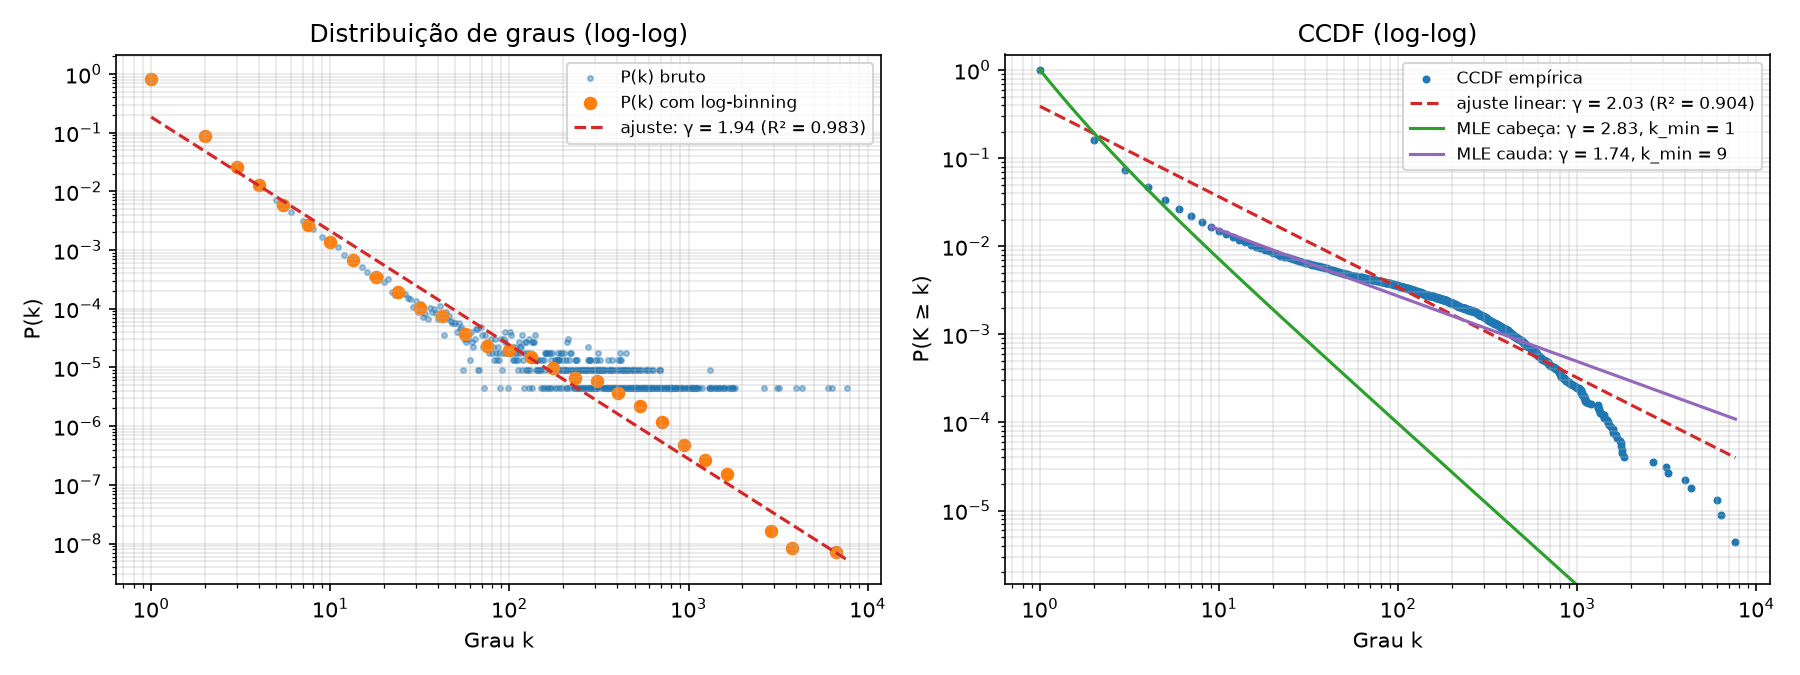

In [11]:
run("powerlaw")
display(table("parte3_powerlaw.csv"))
display(table("parte3_powerlaw_sensibilidade.csv"))
figure("lei_de_potencia.png")

### 4.3 Robustez (remoção de 5% dos vértices)

Ataques por grau, PageRank e betweenness (Brandes, 500 fontes), todos com implementação própria.

,metrica,original,original_estimado,aleatoria_media,aleatoria_desvio,direcionada_grau,direcionada_pagerank,direcionada_betweenness
0,A_fracao_maior_componente,1.00000,1.000000,0.906536,0.016735,0.000027,0.000013,0.000049
1,B_num_componentes,1.00000,1.000000,9431.800000,3484.567290,213167.000000,213395.000000,213263.000000
2,C_caminho_medio,4.11821,4.023927,4.111858,0.040275,1.933333,1.333333,2.290909
3,D_fracao_isolados,0.00000,0.000000,0.044071,0.016312,0.996507,0.998212,0.997776


,top_r,sobreposicao_grau_pagerank,sobreposicao_grau_betweenness,sobreposicao_pagerank_betweenness,fontes_betweenness
0,11242,0.929906,0.685554,0.724782,500


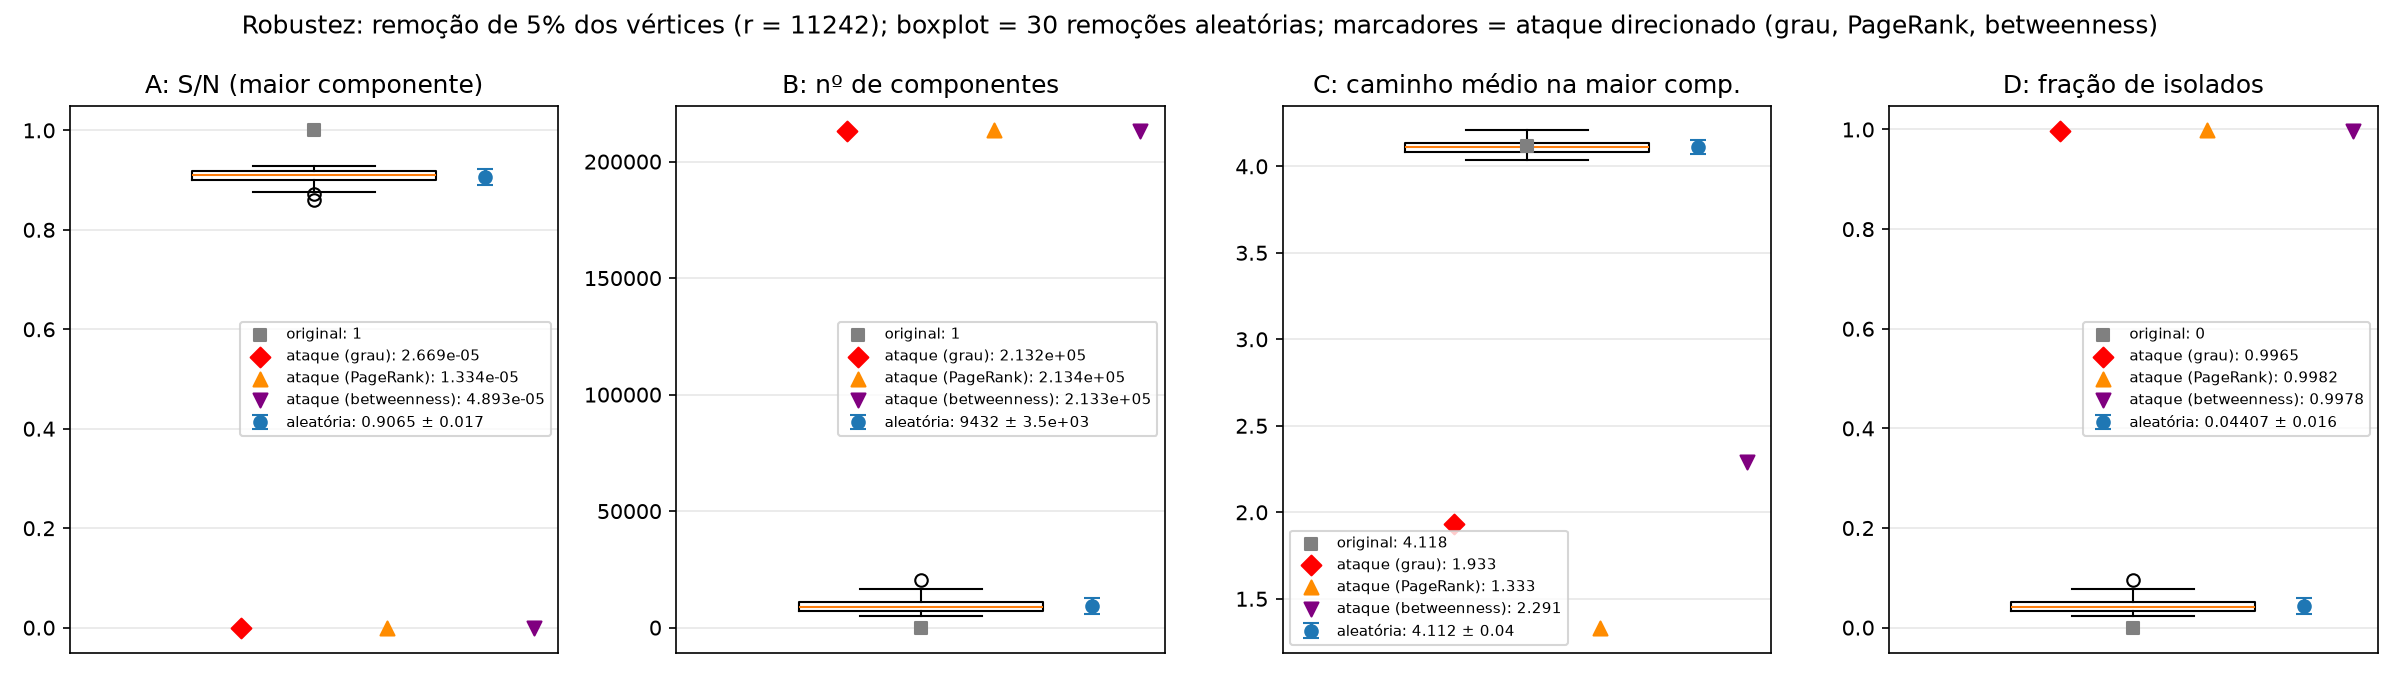

In [12]:
run("centrality")
run("robustness")
display(table("parte3_robustez.csv"))
display(table("parte3_robustez_rankings.csv"))   # sobreposição dos alvos
figure("robustez.png")

### 4.4 Perfil dos maiores hubs (descoberta mais interessante)

In [13]:
run("hubs")
display(table("parte3_hubs.csv"))
table("parte3_hubs_resumo.csv")

,posicao_grau,id_original,grau,destinatarios_saida,remetentes_entrada,frac_vizinhos_folha,pos_pagerank,pos_betweenness
0,1,179170,7636,5,7631,0.999607,1,3
1,2,422,6307,186,6248,0.951482,2,4
2,3,30,6001,195,5948,0.941176,3,5
3,4,72,4308,7,4305,0.965413,4,6
4,5,298,3987,160,3944,0.943316,5,12
5,6,83,3219,929,2695,0.824790,7,10
6,7,485,3119,118,3091,0.971145,6,7
7,8,366,2655,189,2610,0.914878,8,13
8,9,994,1828,71,1794,0.851204,10,20
9,10,406,1771,483,1657,0.495765,19,46


,folhas_na_lcc,folhas_ligadas_aos_top10,fracao_das_folhas_nos_top10,top10_com_mais_remetentes_que_destinatarios
0,188296,37749,0.200477,10


### 4.5 Extra: modelos clássicos (ER, BA e WS gerados por código próprio)

,modelo,n,m,grau_medio,grau_max,fracao_grau1,C,L,fracao_maior_componente,gamma_mle,kmin_mle,ks_mle
0,email-EuAll (LCC),224832,339925,3.023813,7636,0.837496,0.079134,4.117795,1.000000,1.740105,9.0,0.052270
1,"Erdős–Rényi G(n,m)",224832,339925,3.023813,13,0.147048,0.000008,11.066586,0.942103,5.773407,5.0,0.067403
2,Barabási–Albert (m=2),224832,449661,3.999973,954,0.000000,0.000390,6.235701,1.000000,2.871732,11.0,0.006397
3,"Watts–Strogatz (k=4, p=0.1)",224832,449664,4.000000,8,0.000000,0.372141,17.305001,1.000000,NaN,NaN,NaN


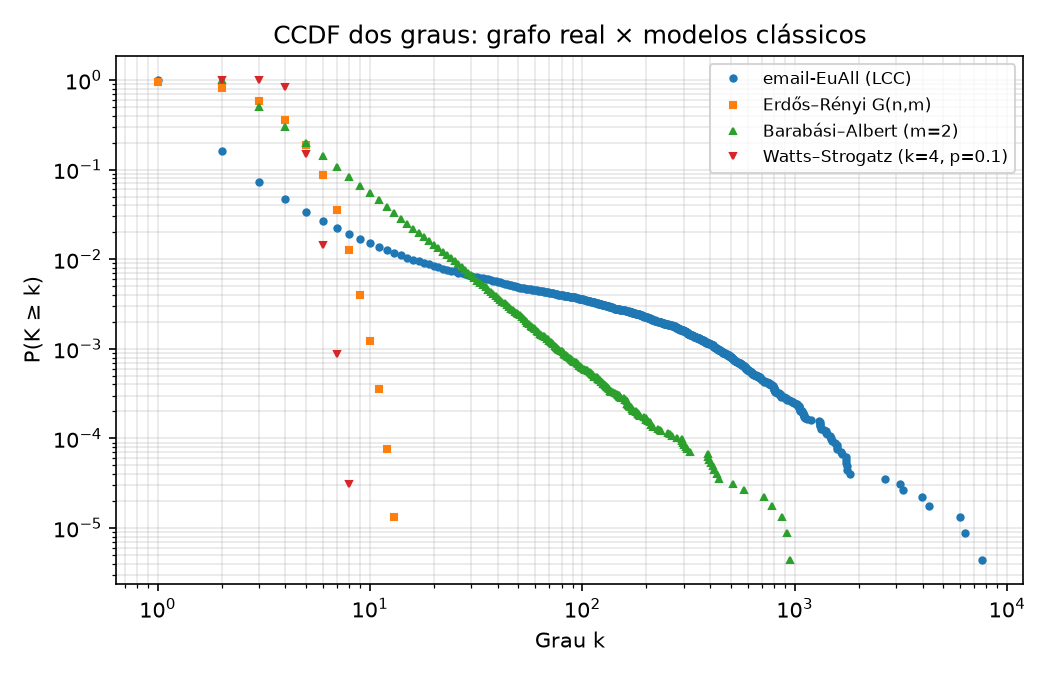

In [14]:
run("models")
display(table("parte3_modelos.csv"))
figure("modelos_ccdf.png", 650)

## 5. Tabelas e números do relatório

Gera `results/latex/tab_*.tex` e `numeros.tex` a partir dos CSVs.

In [15]:
run("report_tables")
print((ROOT / "results" / "latex" / "numeros.tex").read_text(encoding="utf-8")[:1500])

% Gerado por src/report_tables.py a partir de results/tables/ -- não editar
\newcommand{\nVBruto}{265.214}
\newcommand{\nEBruto}{420.045}
\newcommand{\nLoops}{1.089}
\newcommand{\nEUnd}{364.481}
\newcommand{\nRecip}{54.475}
\newcommand{\pctRecip}{26}
\newcommand{\nVLcc}{224.832}
\newcommand{\nELcc}{339.925}
\newcommand{\pctVLcc}{84{,}8}
\newcommand{\pctELcc}{93{,}3}
\newcommand{\nComp}{15.836}
\newcommand{\grauMax}{7.636}
\newcommand{\grauMedioLcc}{3{,}02}
\newcommand{\pctFolhas}{83{,}7}
\newcommand{\diametro}{14}
\newcommand{\raio}{7}
\newcommand{\nBfsDiam}{4}
\newcommand{\Lexato}{4{,}118}
\newcommand{\nBfsLexato}{36.536}
\newcommand{\nFolhasDeduzidas}{188.296}
\newcommand{\minLexato}{22}
\newcommand{\Lamostra}{4{,}127}
\newcommand{\LamostraInf}{4{,}098}
\newcommand{\LamostraSup}{4{,}156}
\newcommand{\Ccompleto}{0{,}0671}
\newcommand{\Clcc}{0{,}0791}
\newcommand{\transit}{0{,}0042}
\newcommand{\triangulos}{267.313}
\newcommand{\tBfs}{0{,}175}
\newcommand{\tDijkstra}{0{,}692}
\newcomma